# Week 10 — Clustering I: K-Means, Elbow Method and Silhouette Score *(In-depth analysis II)*

**Project:** Predicting Loan Repayment Risk Using LendingClub Data

Weeks 4–9 asked *will this loan charge off?* Clustering asks a different question: *what kinds of borrowers are there?* K-Means is fitted on **borrower characteristics only** — no target, no grade, no interest rate — so the clusters cannot simply copy LendingClub's pricing or the outcome. Charge-off rates by cluster then serve as an external check: if segments formed without seeing the outcome still differ in charge-off, they describe risk-relevant structure.

Questions:
1. How many borrower segments does the data support (elbow method, silhouette score)?
2. How do **feature scaling** and the **distance metric** change the clusters?
3. Are the segments stable, and do they differ in charge-off beyond what LendingClub's grade already predicts?

**Protocol.** K-Means and the scaler are fitted on the **training** rows; test loans are only *assigned* to the fitted clusters, so cluster charge-off rates on the test set are an out-of-sample check.

## 0. Setup

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
sns.set_theme(style="whitegrid", font="serif")
pd.set_option("display.float_format", "{:,.4f}".format)
print("scikit-learn", sklearn.__version__)

DATA = Path("data/lc_model_sample.parquet")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
SIL_N = 20_000        # silhouette is O(n²): computed on random training samples of this size
K_RANGE = range(2, 11)
K_CHOSEN = None       # None = choose by the rule in Section 3

# Borrower characteristics only: no target, grade, int_rate, term or purpose
FEATS = ["log_annual_inc", "dti", "fico", "revol_util", "log_revol_bal", "open_acc", "total_acc",
         "credit_hist_years", "emp_length_yrs", "mort_acc", "inq_last_6mths", "loan_amnt"]

scikit-learn 1.9.1


In [2]:
df = pd.read_parquet(DATA)
df[FEATS] = df[FEATS].astype(float)
train, test = df[df.split == "train"].copy(), df[df.split == "test"].copy()
imp = SimpleImputer(strategy="median").fit(train[FEATS])
A_tr, A_te = imp.transform(train[FEATS]), imp.transform(test[FEATS])
scaler = StandardScaler().fit(A_tr)
Z_tr, Z_te = scaler.transform(A_tr), scaler.transform(A_te)
rng = np.random.default_rng(RANDOM_STATE)
sil_samples = [rng.choice(len(Z_tr), SIL_N, replace=False) for _ in range(3)]
print(f"train {Z_tr.shape} | test {Z_te.shape} | features: {len(FEATS)}")
train[FEATS].describe().T[["mean", "std", "min", "max"]]

train (140000, 12) | test (60000, 12) | features: 12


,mean,std,min,max
log_annual_inc,11.0395,0.5438,7.4793,15.9556
dti,17.5137,8.1776,0.0000,60.0800
fico,697.4895,31.1798,627.0000,847.5000
revol_util,54.1041,23.9474,0.0000,177.7000
log_revol_bal,9.1931,1.1665,0.0000,14.7590
open_acc,11.2407,5.1880,0.0000,62.0000
total_acc,24.6230,11.7473,1.0000,156.0000
credit_hist_years,16.0580,7.5234,0.5804,71.0007
emp_length_yrs,5.8789,3.6599,0.0000,10.0000
mort_acc,1.6667,2.0615,0.0000,29.0000


## 1. Feature scaling

K-Means assigns each loan to the nearest centroid in squared Euclidean distance, so a feature measured in thousands of dollars dominates one measured in years or counts. With raw units, `loan_amnt` (sd ≈ 8,000) controls the distance, and the "clusters" are loan-size bands. Standardizing gives every feature unit variance; `RobustScaler` (median and IQR) is less influenced by outliers. All three are compared at k = 4.

In [3]:
var_share = pd.Series(A_tr.var(0) / A_tr.var(0).sum(), index=FEATS).sort_values(ascending=False)
print("Share of total raw variance:\n", var_share.head(3).round(4).to_string())
scal_rows, scal_labels = [], {}
for name, M in [("raw units", A_tr), ("StandardScaler", Z_tr), ("RobustScaler", RobustScaler().fit_transform(A_tr))]:
    km = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit(M)
    scal_labels[name] = km.labels_
    centers = pd.DataFrame(km.cluster_centers_, columns=FEATS)
    spread = (centers.max() - centers.min()) / pd.DataFrame(M, columns=FEATS).std()
    scal_rows.append({"scaling": name, "silhouette (own units)": silhouette_score(M[sil_samples[0]], km.labels_[sil_samples[0]]),
                      "feature separating clusters most": spread.idxmax(),
                      "charge-off rate range": train["target"].groupby(km.labels_).mean().max() - train["target"].groupby(km.labels_).mean().min()})
scal_tab = pd.DataFrame(scal_rows).set_index("scaling")
scal_tab["ARI vs StandardScaler"] = [adjusted_rand_score(scal_labels["StandardScaler"], scal_labels[n]) for n in scal_tab.index]
scal_tab

Share of total raw variance:
 loan_amnt    1.0000
fico         0.0000
revol_util   0.0000


,silhouette (own units),feature separating clusters most,charge-off rate range,ARI vs StandardScaler
scaling,,,,
raw units,0.5630,loan_amnt,0.0115,0.1035
StandardScaler,0.1228,total_acc,0.0703,1.0000
RobustScaler,0.1414,inq_last_6mths,0.0946,0.4858


## 2. Elbow method and silhouette score, k = 2–10

* **Inertia** (within-cluster sum of squared distances) always falls as k grows; the *elbow* is where extra clusters stop buying much.
* **Silhouette** for one loan is (b − a) / max(a, b), where a is its mean distance to its own cluster and b to the nearest other cluster. It ranges from −1 to 1; near 0 means the loan sits on a boundary. The mean silhouette rewards compact, well-separated clusters (Rousseeuw, 1987). It is computed on three independent 20,000-loan samples to check that the ranking is not a sampling accident.
* **Davies–Bouldin** (lower is better) is a third, cheaper index.

`n_init = 10` runs K-Means from 10 random k-means++ starts and keeps the lowest-inertia solution, guarding against a poor local minimum.

In [4]:
rows, models = [], {}
for k in K_RANGE:
    t0 = time.time()
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Z_tr); models[k] = km
    sils = [silhouette_score(Z_tr[s], km.labels_[s]) for s in sil_samples]
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": np.mean(sils), "silhouette_sd": np.std(sils),
                 "davies_bouldin": davies_bouldin_score(Z_tr[sil_samples[0]], km.labels_[sil_samples[0]]),
                 "smallest cluster share": np.bincount(km.labels_).min() / len(km.labels_), "seconds": time.time() - t0})
elbow = pd.DataFrame(rows).set_index("k")
elbow["inertia drop %"] = -elbow["inertia"].pct_change() * 100
elbow

,inertia,silhouette,silhouette_sd,davies_bouldin,smallest cluster share,seconds,inertia drop %
k,,,,,,,
2,"1,423,627.8991",0.1512,0.0009,2.2373,0.4346,11.2717,NaN
3,"1,315,545.9402",0.1260,0.0013,2.1683,0.1913,11.4963,7.5920
4,"1,235,460.6575",0.1224,0.0011,2.2812,0.1569,11.5500,6.0876
5,"1,178,011.2527",0.0886,0.0007,2.2816,0.1270,11.5733,4.6500
6,"1,131,398.4900",0.0906,0.0006,2.1547,0.1015,12.1512,3.9569
7,"1,089,208.6474",0.0919,0.0010,2.1427,0.0911,12.0943,3.7290
8,"1,052,295.6961",0.0857,0.0006,2.0417,0.0830,12.6744,3.3890
9,"1,017,489.0970",0.0920,0.0010,1.9534,0.0123,12.8984,3.3077
10,"990,035.4206",0.0908,0.0013,1.9037,0.0110,14.2445,2.6982


## 3. Choosing k

Rule: take the k with the highest mean silhouette among k ≥ 3, unless k = 2 is higher by more than its sampling noise — a two-way split of borrowers is rarely useful to a lender, and the silhouette is often largest at k = 2 simply because one split is easiest. The elbow plot is used as a cross-check.

In [5]:
if K_CHOSEN is None:
    k3 = elbow.loc[3:, "silhouette"].idxmax()
    K_CHOSEN = 2 if elbow.loc[2, "silhouette"] - elbow.loc[k3, "silhouette"] > 2 * elbow.loc[2, "silhouette_sd"] + 0.01 else int(k3)
print(f"Chosen k = {K_CHOSEN}: silhouette {elbow.loc[K_CHOSEN, 'silhouette']:.3f} (sd across samples {elbow.loc[K_CHOSEN, 'silhouette_sd']:.3f})")

Chosen k = 2: silhouette 0.151 (sd across samples 0.001)


In [6]:
# Silhouette under other distance metrics for the same labels (K-Means itself optimizes squared Euclidean distance)
km = models[K_CHOSEN]; s = sil_samples[0]
metric_sil = pd.Series({m: silhouette_score(Z_tr[s], km.labels_[s], metric=m) for m in ["euclidean", "manhattan", "cosine"]}, name=f"silhouette, k={K_CHOSEN}")
metric_sil.to_frame()

,"silhouette, k=2"
euclidean,0.1512
manhattan,0.1689
cosine,0.2562


## 4. Stability (the clustering analogue of overfitting)

K-Means has no test error, but it can still "overfit" by producing clusters that belong to one random start or one sample. Two checks: (1) refit with five different seeds and compare labels with the adjusted Rand index (ARI = 1 identical, ≈ 0 chance); (2) fit on two disjoint halves of the training rows and compare how each assigns *all* training loans.

In [7]:
base = models[K_CHOSEN].labels_
seed_ari = [adjusted_rand_score(base, KMeans(K_CHOSEN, n_init=10, random_state=s).fit(Z_tr).labels_) for s in [1, 2, 3, 4, 5]]
half = rng.permutation(len(Z_tr)); h1, h2 = half[: len(half) // 2], half[len(half) // 2:]
lab1 = KMeans(K_CHOSEN, n_init=10, random_state=RANDOM_STATE).fit(Z_tr[h1]).predict(Z_tr)
lab2 = KMeans(K_CHOSEN, n_init=10, random_state=RANDOM_STATE).fit(Z_tr[h2]).predict(Z_tr)
stab = {"ARI across 5 seeds (mean)": np.mean(seed_ari), "ARI across 5 seeds (min)": np.min(seed_ari), "ARI half A vs half B": adjusted_rand_score(lab1, lab2)}
pd.Series(stab).to_frame("value")

,value
ARI across 5 seeds (mean),0.9921
ARI across 5 seeds (min),0.9888
ARI half A vs half B,0.9772


## 5. Cluster profiles and charge-off

Profiles are in original units. Charge-off is shown for training loans and for test loans assigned to the fitted centroids. **Expected** charge-off is what each cluster's grade mix would predict using training charge-off rates by grade; observed ÷ expected above 1 means the segment charged off more than its LendingClub grades implied.

In [8]:
km = models[K_CHOSEN]
train["cluster"] = km.labels_; test["cluster"] = km.predict(Z_te)
grade_rate = train.groupby("grade")["target"].mean()
train["exp_rate"] = train["grade"].map(grade_rate); test["exp_rate"] = test["grade"].map(grade_rate)
prof = train.groupby("cluster")[FEATS].median()
prof.insert(0, "share", train["cluster"].value_counts(normalize=True).sort_index())
prof["int_rate (mean)"] = train.groupby("cluster")["int_rate"].mean()
prof["share 60-month"] = train.assign(t60=train["term"].astype(str).str.contains("60")).groupby("cluster")["t60"].mean()
prof["charge-off (train)"] = train.groupby("cluster")["target"].mean()
prof["charge-off (test)"] = test.groupby("cluster")["target"].mean()
prof["expected from grade (test)"] = test.groupby("cluster")["exp_rate"].mean()
prof["observed / expected (test)"] = prof["charge-off (test)"] / prof["expected from grade (test)"]
prof["test loans"] = test["cluster"].value_counts().sort_index()
prof = prof.sort_values("charge-off (train)")
prof.to_csv(RES_DIR / "week10_cluster_profiles.csv")
prof.T

cluster,0,1
share,0.4346,0.5654
log_annual_inc,11.3386,10.7996
dti,18.3300,15.9200
fico,697.0000,687.0000
revol_util,56.3000,53.8000
log_revol_bal,9.8314,8.9267
open_acc,13.0000,9.0000
total_acc,31.0000,18.0000
credit_hist_years,18.0835,12.2519
emp_length_yrs,9.0000,5.0000


In [9]:
# Is the observed/expected gap more than noise? Binomial standard error on the test set
pe = prof[["charge-off (test)", "expected from grade (test)", "test loans"]].copy()
pe["se"] = np.sqrt(pe["expected from grade (test)"] * (1 - pe["expected from grade (test)"]) / pe["test loans"])
pe["z (observed − expected)"] = (pe["charge-off (test)"] - pe["expected from grade (test)"]) / pe["se"]
pe

,charge-off (test),expected from grade (test),test loans,se,z (observed − expected)
cluster,,,,,
0,0.1336,0.1404,26073,0.0022,-3.1696
1,0.1603,0.1554,33927,0.0020,2.4481


In [10]:
# Name clusters from their standardized centroids (largest deviations), for the report
cz = pd.DataFrame(km.cluster_centers_, columns=FEATS).loc[prof.index]
def describe(row, n=3):
    top = row.abs().sort_values(ascending=False).index[:n]
    return ", ".join(f"{'high' if row[f] > 0 else 'low'} {f}" for f in top)
names = pd.Series({c: describe(cz.loc[c]) for c in cz.index}, name="defining features (vs average)")
names.to_frame()

,defining features (vs average)
0,"high total_acc, high log_annual_inc, high loan..."
1,"low total_acc, low log_annual_inc, low loan_amnt"


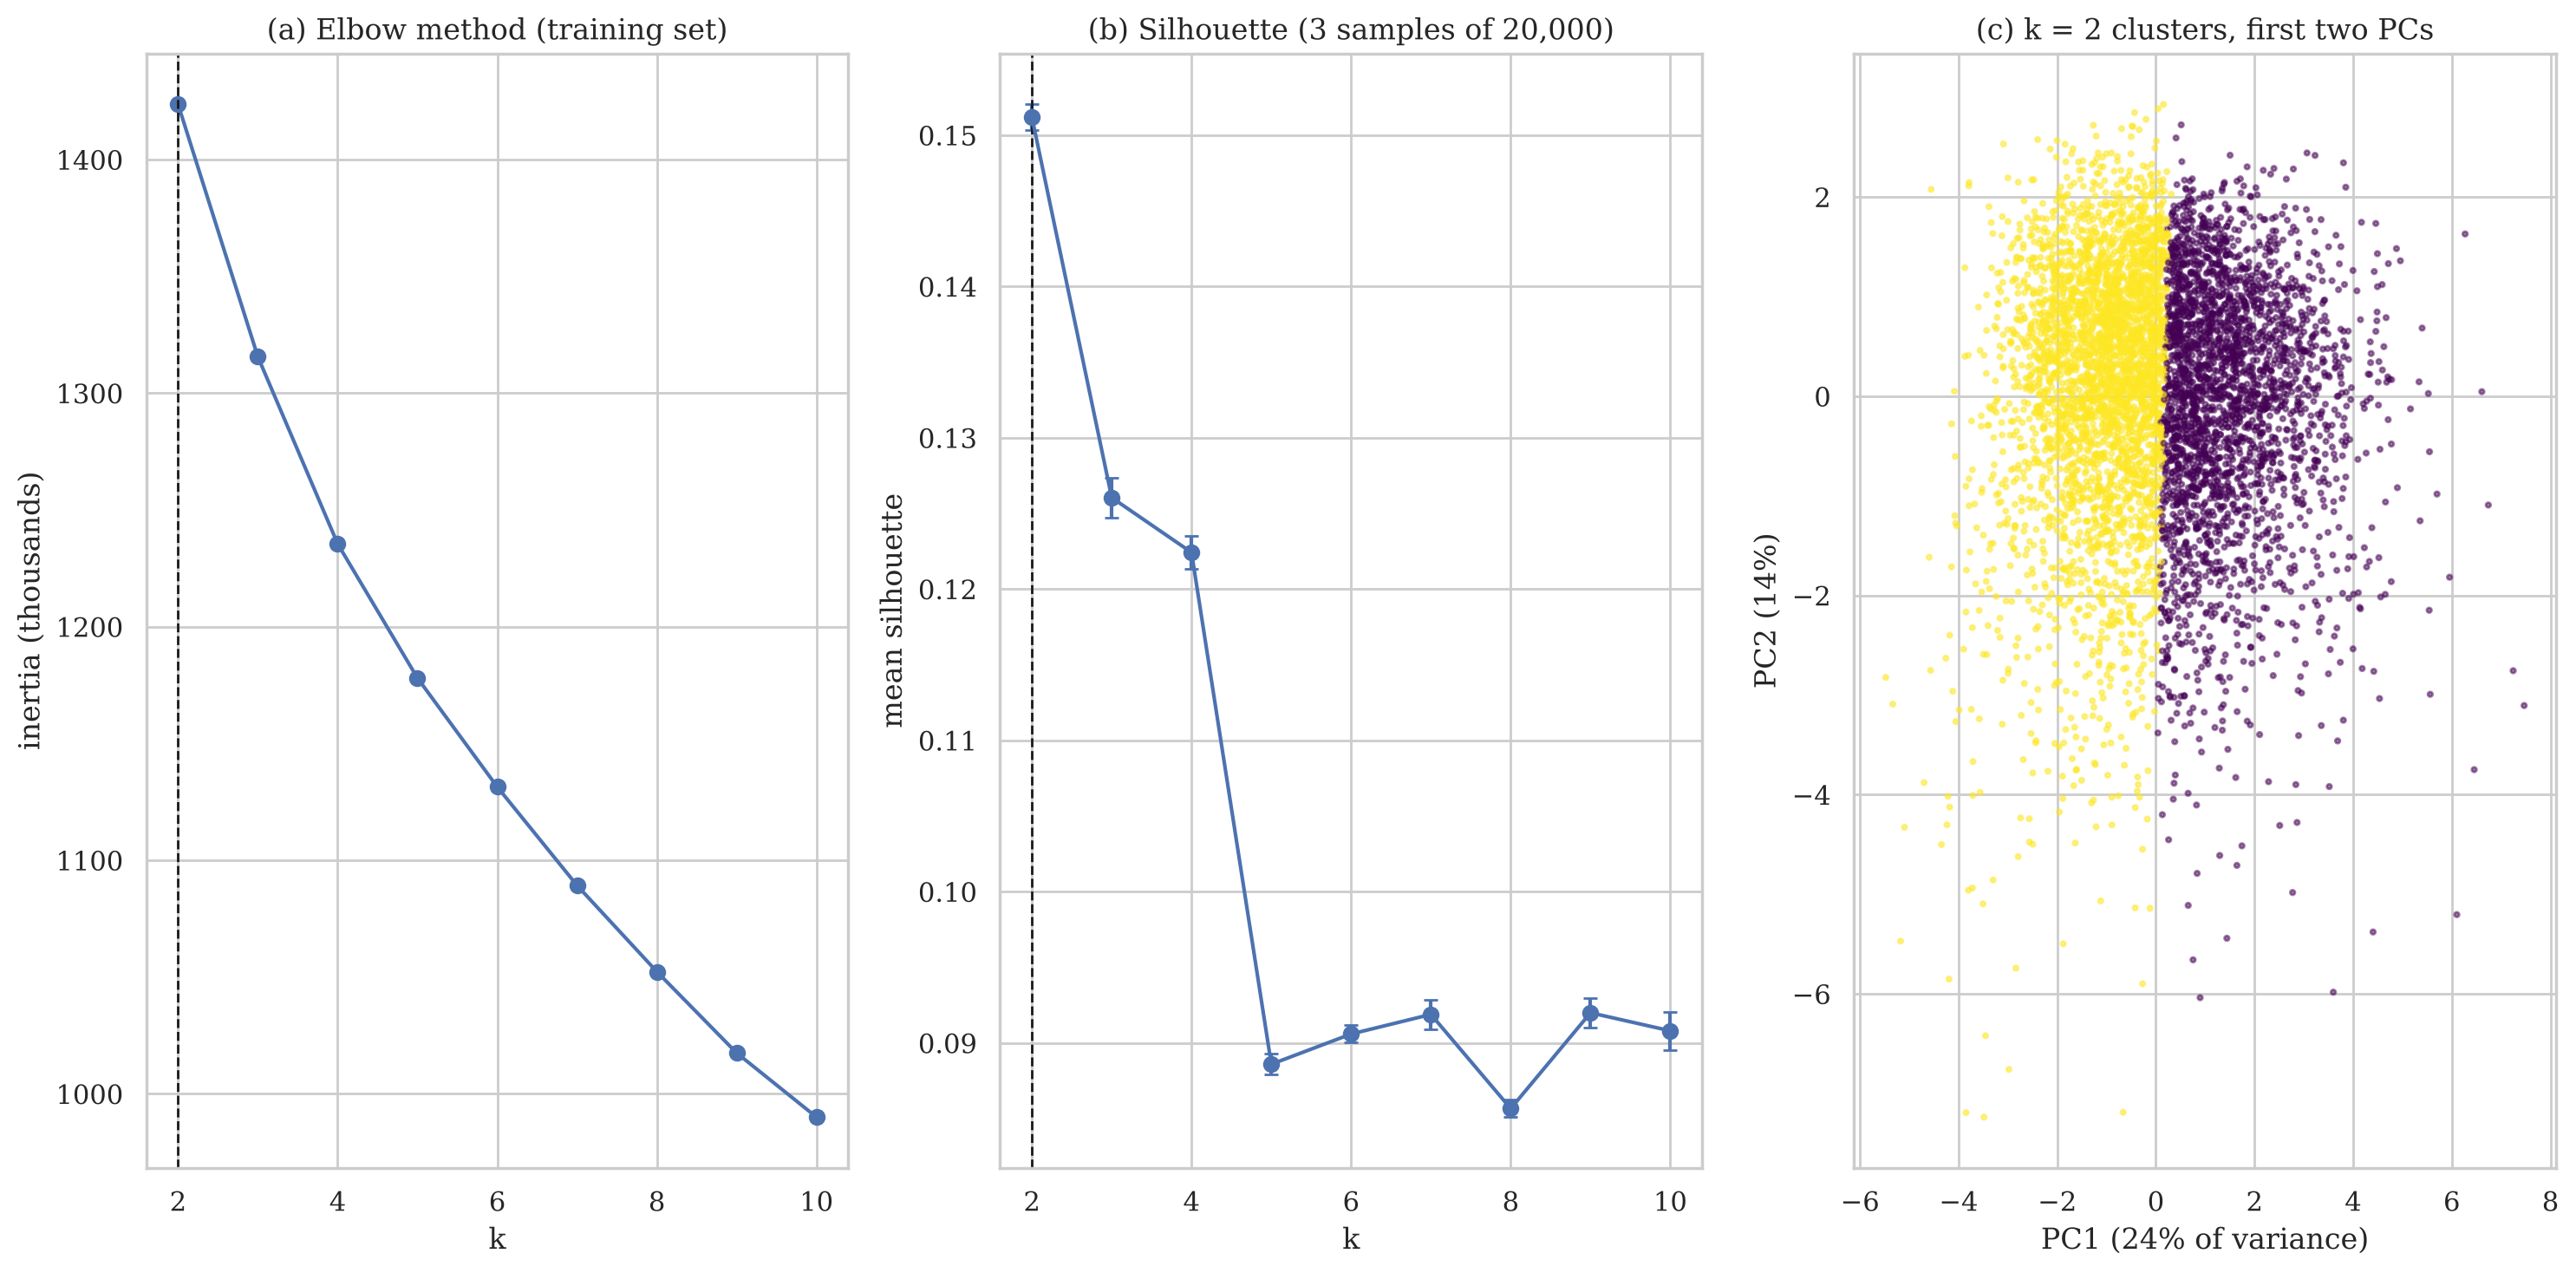

In [11]:
# Figure for the report: elbow + silhouette (left, middle) and PCA view of the clusters (right)
fig, axes = plt.subplots(1, 3, figsize=(15, 7.5))
axes[0].plot(elbow.index, elbow["inertia"] / 1e3, marker="o"); axes[0].axvline(K_CHOSEN, ls="--", c="k", lw=1)
axes[0].set(xlabel="k", ylabel="inertia (thousands)", title="(a) Elbow method (training set)")
axes[1].errorbar(elbow.index, elbow["silhouette"], yerr=elbow["silhouette_sd"], marker="o", capsize=3); axes[1].axvline(K_CHOSEN, ls="--", c="k", lw=1)
axes[1].set(xlabel="k", ylabel="mean silhouette", title=f"(b) Silhouette (3 samples of {SIL_N:,})")
pca = PCA(2, random_state=RANDOM_STATE).fit(Z_tr); P = pca.transform(Z_tr[sil_samples[0][:6000]])
lab = km.labels_[sil_samples[0][:6000]]
order = {c: i for i, c in enumerate(prof.index)}
sc = axes[2].scatter(P[:, 0], P[:, 1], c=[order[l] for l in lab], cmap="viridis", s=4, alpha=0.5)
axes[2].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
            title=f"(c) k = {K_CHOSEN} clusters, first two PCs")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_kmeans_elbow_silhouette.png", dpi=200); plt.show()

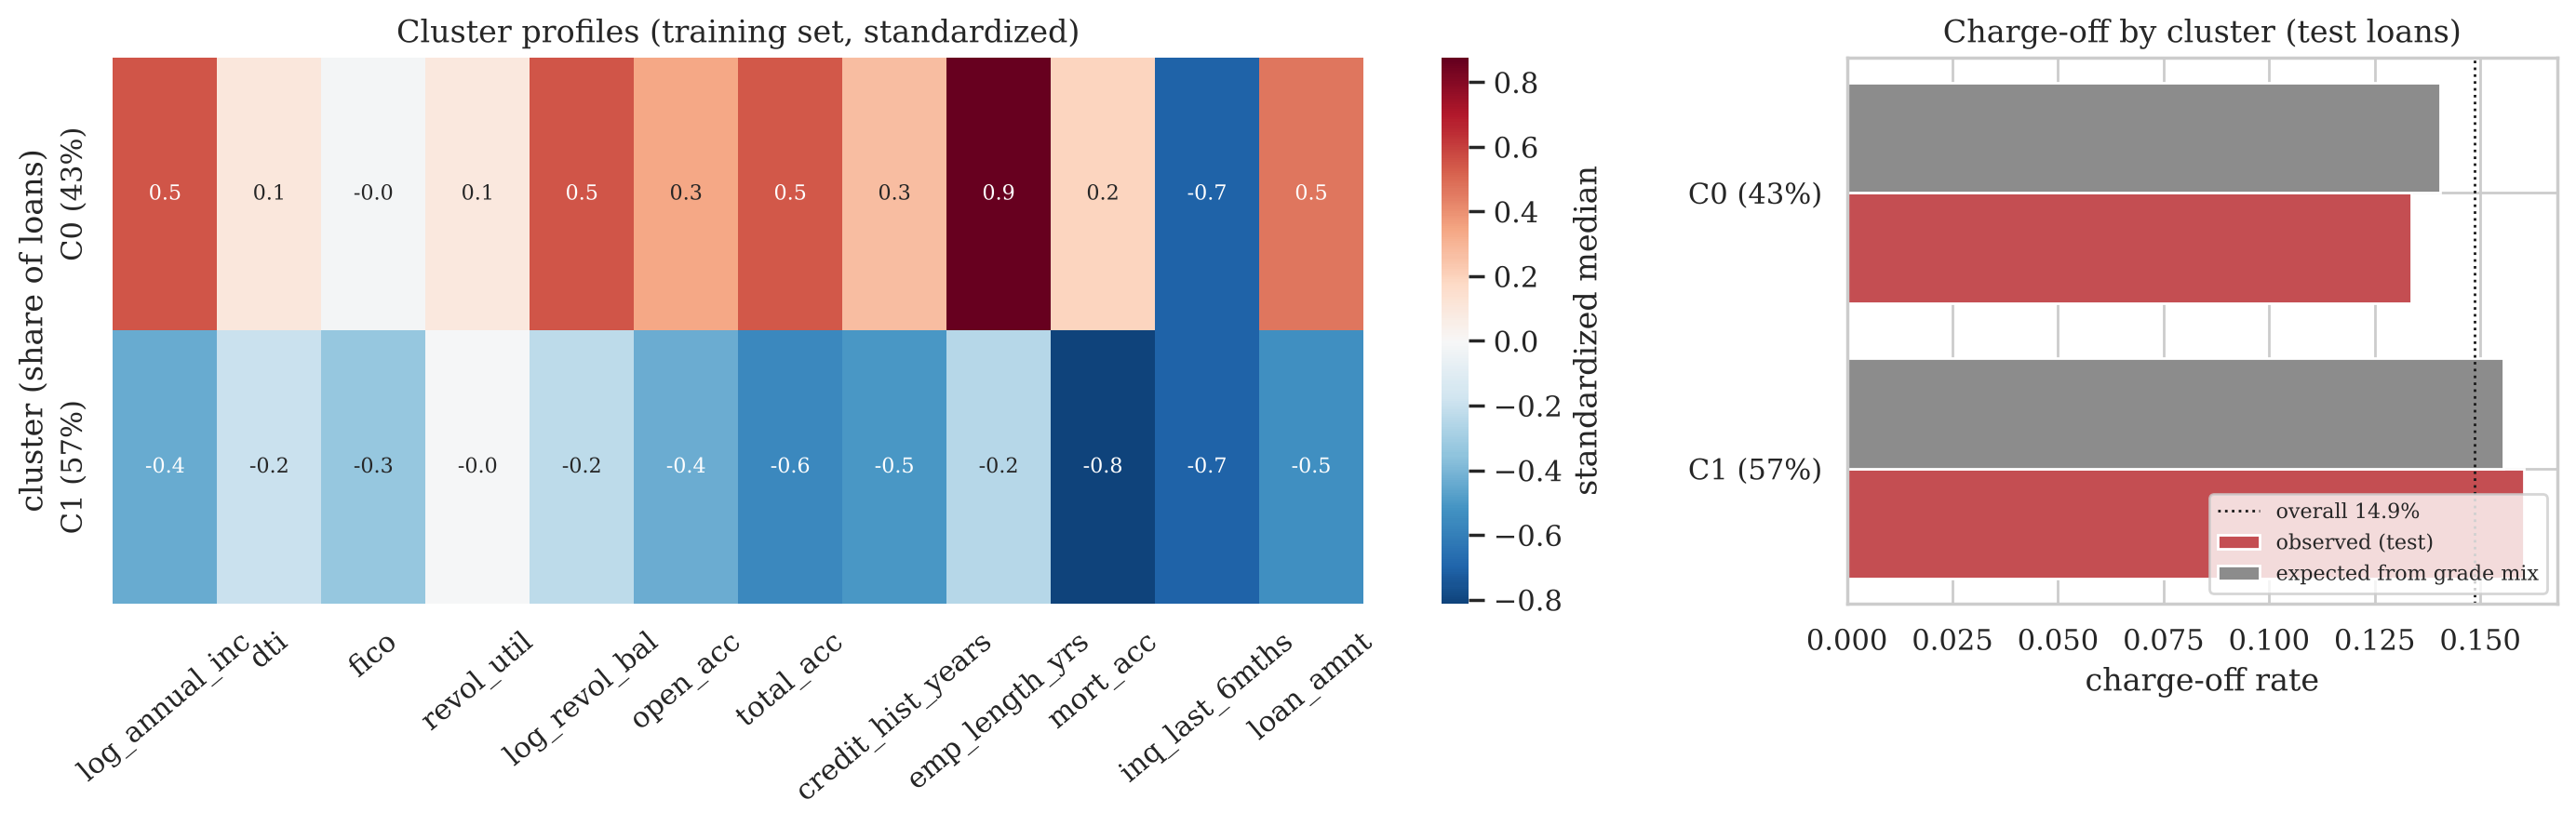

In [12]:
# Figure for the report: cluster profile heatmap (standardized medians) + charge-off observed vs expected
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
zprof = pd.DataFrame(scaler.transform(prof[FEATS].values), index=prof.index, columns=FEATS)
labels_y = [f"C{c} ({prof.loc[c, 'share']:.0%})" for c in prof.index]
sns.heatmap(zprof, ax=axes[0], cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 8}, cbar_kws={"label": "standardized median"},
            yticklabels=labels_y)
axes[0].set(title="Cluster profiles (training set, standardized)", ylabel="cluster (share of loans)"); axes[0].tick_params(axis="x", rotation=40)
y = np.arange(len(prof))
axes[1].barh(y + 0.2, prof["charge-off (test)"], 0.4, label="observed (test)", color="#C44E52")
axes[1].barh(y - 0.2, prof["expected from grade (test)"], 0.4, label="expected from grade mix", color="#8C8C8C")
axes[1].set_yticks(y, labels_y); axes[1].invert_yaxis()
axes[1].axvline(test["target"].mean(), ls=":", c="k", lw=1, label=f"overall {test['target'].mean():.1%}")
axes[1].set(xlabel="charge-off rate", title="Charge-off by cluster (test loans)"); axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_kmeans_profiles.png", dpi=200); plt.show()

## 5b. A finer segmentation: k = 4 (secondary view)

The silhouette favors k = 2, but the inertia curve has no sharp elbow and two segments give a lender little to act on. k = 4 (silhouette within about 0.03 of k = 2–3) is profiled the same way as a secondary view; k = 2 remains the reported choice. The crosstab shows how the four clusters nest inside the two.

In [13]:
km4 = models[4]
train["cluster4"] = km4.labels_; test["cluster4"] = km4.predict(Z_te)
prof4 = train.groupby("cluster4")[FEATS].median()
prof4.insert(0, "share", train["cluster4"].value_counts(normalize=True).sort_index())
prof4["int_rate (mean)"] = train.groupby("cluster4")["int_rate"].mean()
prof4["share 60-month"] = train.assign(t60=train["term"].astype(str).str.contains("60")).groupby("cluster4")["t60"].mean()
prof4["charge-off (train)"] = train.groupby("cluster4")["target"].mean()
prof4["charge-off (test)"] = test.groupby("cluster4")["target"].mean()
prof4["expected from grade (test)"] = test.groupby("cluster4")["exp_rate"].mean()
prof4["observed / expected (test)"] = prof4["charge-off (test)"] / prof4["expected from grade (test)"]
prof4["test loans"] = test["cluster4"].value_counts().sort_index()
se4 = np.sqrt(prof4["expected from grade (test)"] * (1 - prof4["expected from grade (test)"]) / prof4["test loans"])
prof4["z (observed − expected)"] = (prof4["charge-off (test)"] - prof4["expected from grade (test)"]) / se4
prof4 = prof4.sort_values("charge-off (train)")
prof4.to_csv(RES_DIR / "week10_cluster_profiles_k4.csv")
print(pd.crosstab(train["cluster4"], train["cluster"], normalize="index").round(2))
prof4.T

cluster       0      1
cluster4              
0        0.8500 0.1500
1        0.0300 0.9700
2        0.9400 0.0600
3        0.1800 0.8200


cluster4,3,2,0,1
share,0.1569,0.2383,0.2010,0.4038
log_annual_inc,11.0021,11.4927,11.0822,10.7579
dti,11.1600,15.4300,22.8300,17.4200
fico,732.0000,697.0000,687.0000,682.0000
revol_util,21.7000,64.2000,48.4000,63.3000
log_revol_bal,8.3450,9.9962,9.5913,9.0772
open_acc,9.0000,11.0000,17.0000,8.0000
total_acc,20.0000,27.0000,37.0000,17.0000
credit_hist_years,13.6619,18.7461,16.5804,12.0000
emp_length_yrs,5.0000,9.0000,7.0000,5.0000


In [14]:
cz4 = pd.DataFrame(km4.cluster_centers_, columns=FEATS).loc[prof4.index]
pd.Series({c: describe(cz4.loc[c], 4) for c in cz4.index}, name="defining features (vs average)").to_frame()

,defining features (vs average)
3,"low revol_util, high fico, low log_revol_bal, ..."
2,"high loan_amnt, high log_annual_inc, high mort..."
0,"high open_acc, high total_acc, high dti, high ..."
1,"low total_acc, low log_annual_inc, low open_ac..."


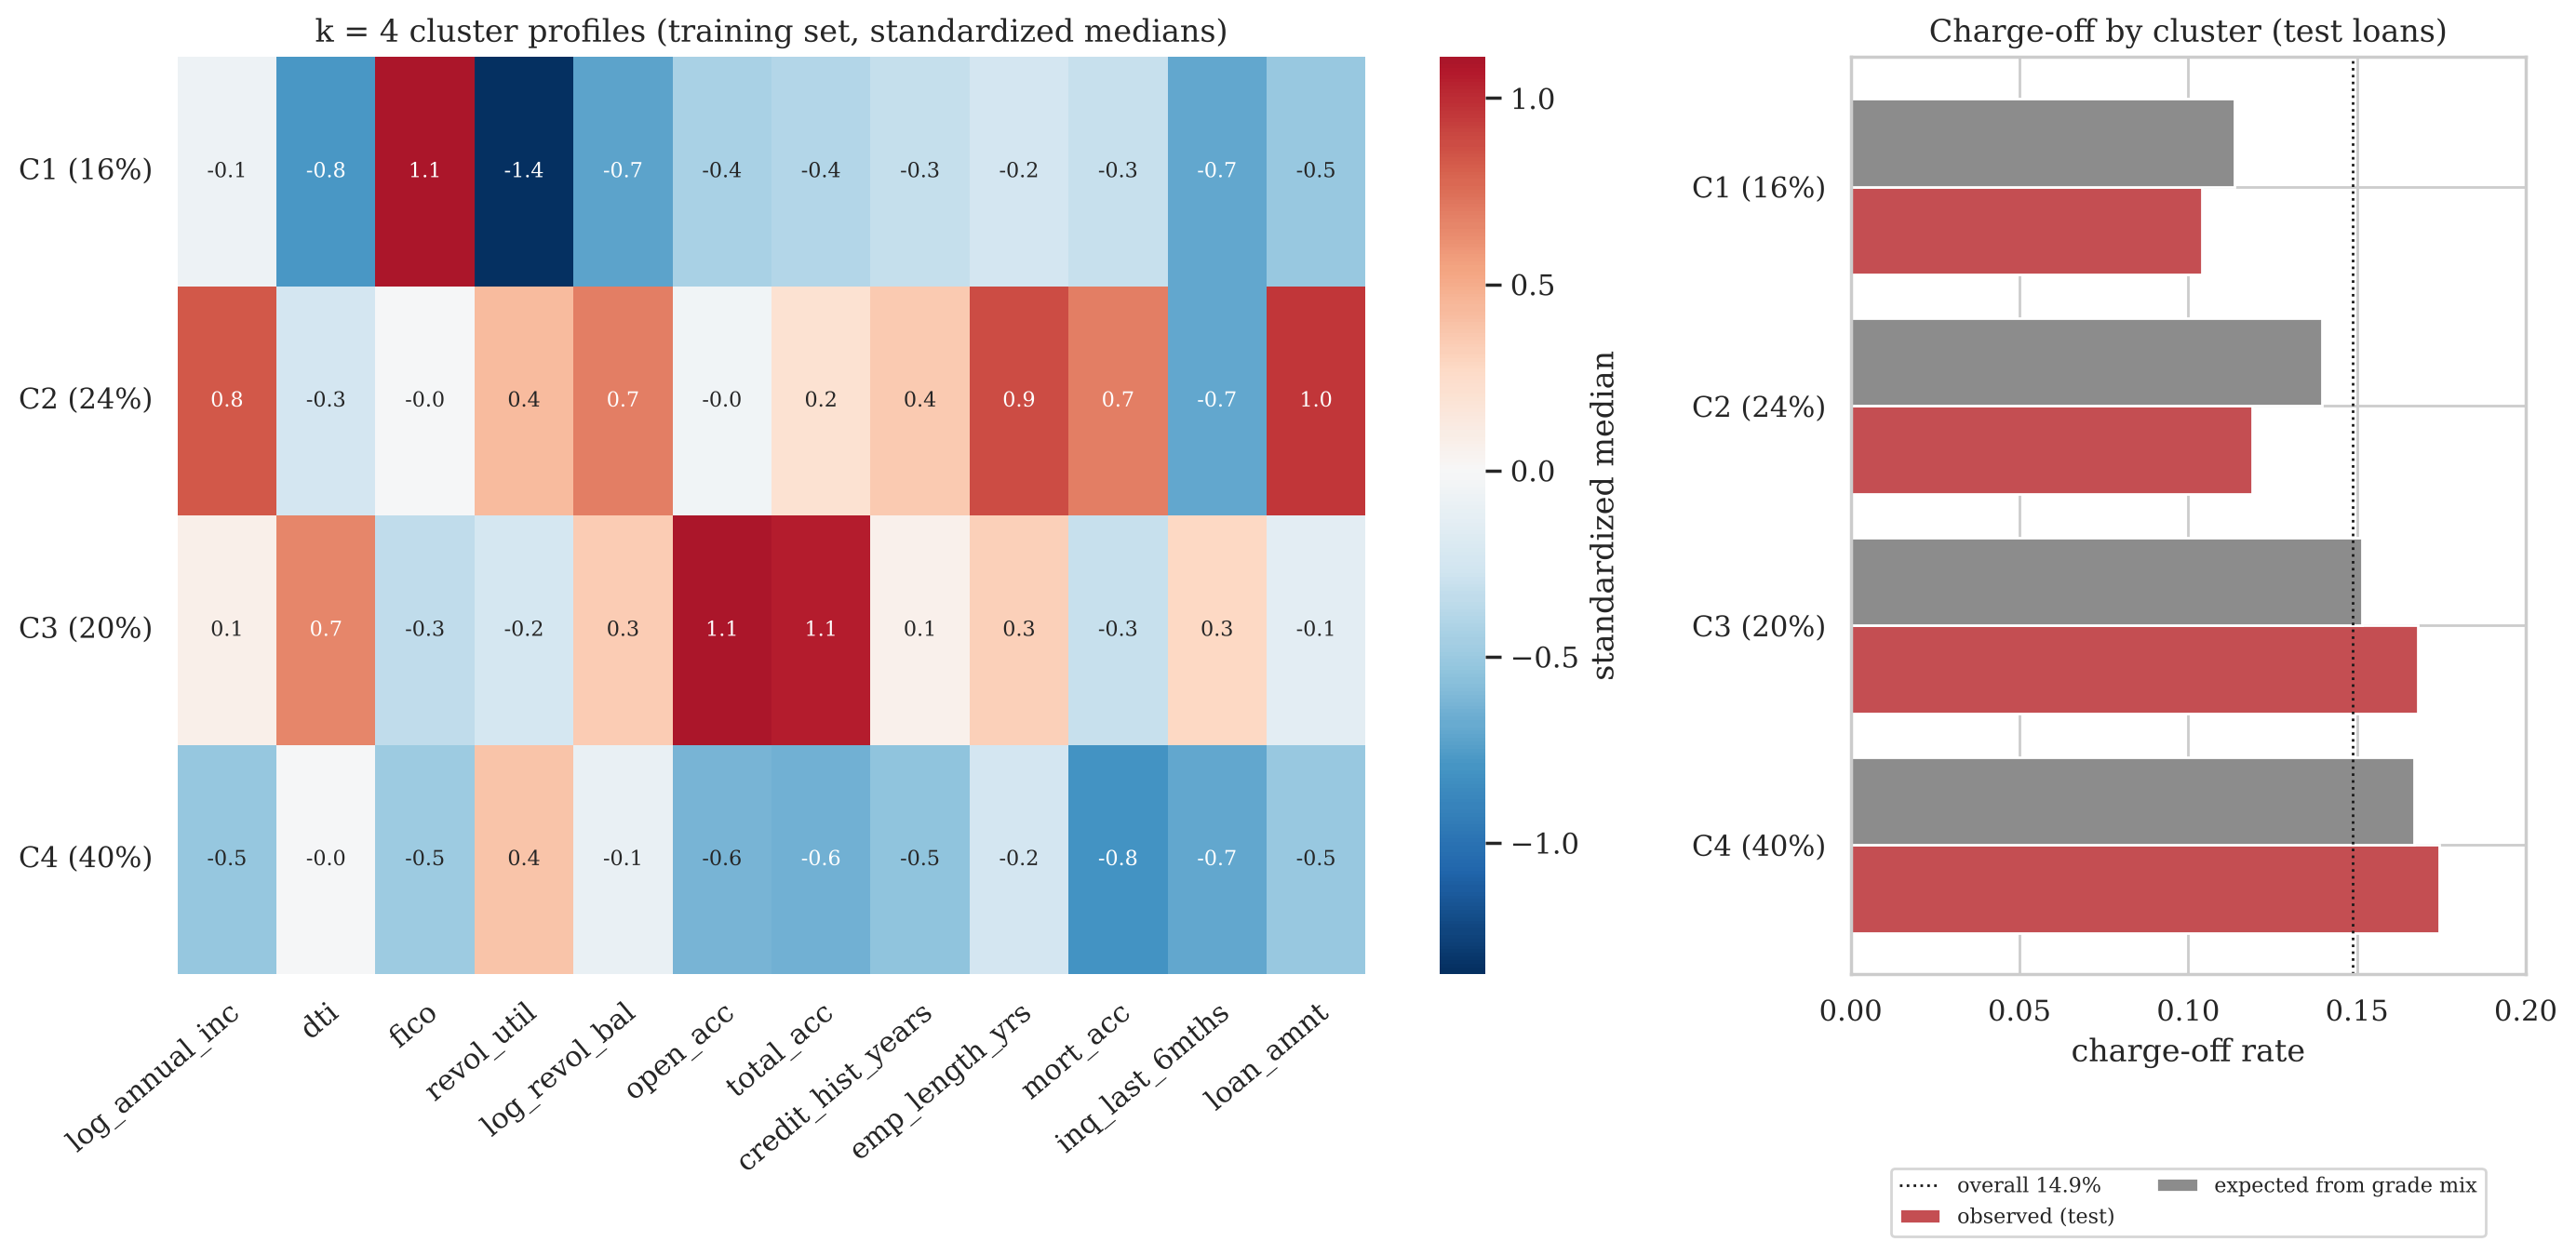

In [15]:
# Figure for the report: k = 4 profile heatmap + charge-off observed vs expected from grade
fig, axes = plt.subplots(1, 2, figsize=(14, 7.0), gridspec_kw={"width_ratios": [2.2, 1]})
zp4 = pd.DataFrame(scaler.transform(prof4[FEATS].values), index=prof4.index, columns=FEATS)
ly4 = [f"C{i+1} ({prof4.loc[c, 'share']:.0%})" for i, c in enumerate(prof4.index)]
sns.heatmap(zp4, ax=axes[0], cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 8},
            cbar_kws={"label": "standardized median"}, yticklabels=ly4)
axes[0].set(title="k = 4 cluster profiles (training set, standardized medians)", ylabel=""); axes[0].tick_params(axis="y", rotation=0)
plt.setp(axes[0].get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
y4 = np.arange(len(prof4))
axes[1].barh(y4 + 0.2, prof4["charge-off (test)"], 0.4, label="observed (test)", color="#C44E52")
axes[1].barh(y4 - 0.2, prof4["expected from grade (test)"], 0.4, label="expected from grade mix", color="#8C8C8C")
axes[1].set_yticks(y4, ly4); axes[1].invert_yaxis()
axes[1].axvline(test["target"].mean(), ls=":", c="k", lw=1, label=f"overall {test['target'].mean():.1%}")
axes[1].set(xlabel="charge-off rate", title="Charge-off by cluster (test loans)", xlim=(0, 0.2)); axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_kmeans_profiles_k4.png", dpi=200); plt.show()

## 6. Do the clusters add information to the Week 4 logistic regression?

If cluster membership only restates the features, adding it as a one-hot predictor should not change cross-validated ROC-AUC.

In [16]:
NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "fico", "inq_last_6mths", "delinq_2yrs", "open_acc",
       "total_acc", "revol_util", "log_revol_bal", "pub_rec", "mort_acc", "pub_rec_bankruptcies",
       "credit_hist_years", "emp_length_yrs", "ever_delinq"]
CAT = ["term", "grade", "home_ownership", "verification_status", "purpose", "application_type", "initial_list_status"]
for d in (train, test):
    d[NUM] = d[NUM].astype(float)
    for c in CAT: d[c] = d[c].astype("string").fillna("Missing").astype(object)
    d["cluster_cat"] = d["cluster"].astype(str)
CAT = [c for c in CAT if train[c].nunique() > 1]
def lr_pipe(cat):
    return Pipeline([("pre", ColumnTransformer([("num", Pipeline([("i", SimpleImputer(strategy="median", add_indicator=True)), ("s", StandardScaler())]), NUM),
                                                ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), cat)])),
                     ("clf", LogisticRegression(C=0.1, max_iter=5000))])
CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
y_tr = train["target"].astype(int)
auc_base = cross_val_score(lr_pipe(CAT), train[NUM + CAT], y_tr, cv=CV, scoring="roc_auc").mean()
auc_clu = cross_val_score(lr_pipe(CAT + ["cluster_cat"]), train[NUM + CAT + ["cluster_cat"]], y_tr, cv=CV, scoring="roc_auc").mean()
print(f"Logistic regression CV ROC-AUC: {auc_base:.4f} without clusters | {auc_clu:.4f} with cluster one-hot ({auc_clu - auc_base:+.4f})")

Logistic regression CV ROC-AUC: 0.6839 without clusters | 0.6838 with cluster one-hot (-0.0000)


In [17]:
pd.DataFrame({"id": train["id"], "cluster": train["cluster"]}).to_parquet(RES_DIR / "week10_train_clusters.parquet", index=False)
summary = {"k": K_CHOSEN, "silhouette": elbow.loc[K_CHOSEN, "silhouette"], "silhouette_k2": elbow.loc[2, "silhouette"],
           "best_silhouette_k": int(elbow["silhouette"].idxmax()), **stab, **{f"sil_{m}": v for m, v in metric_sil.items()},
           "lr_auc_base": auc_base, "lr_auc_clusters": auc_clu, "raw_var_share_top": var_share.index[0], "raw_var_share": var_share.iloc[0]}
pd.Series(summary).to_csv(RES_DIR / "week10_summary.csv")
pd.Series(summary)

k                                    2
silhouette                      0.1512
silhouette_k2                   0.1512
best_silhouette_k                    2
ARI across 5 seeds (mean)       0.9921
ARI across 5 seeds (min)        0.9888
ARI half A vs half B            0.9772
sil_euclidean                   0.1512
sil_manhattan                   0.1689
sil_cosine                      0.2562
lr_auc_base                     0.6839
lr_auc_clusters                 0.6838
raw_var_share_top            loan_amnt
raw_var_share                   1.0000
dtype: object

## 7. Conclusions

**Scaling.** In raw units `loan_amnt` holds essentially all of the variance (share 1.000 to four decimals), so K-Means simply cut loans into size bands. That solution has the *highest* silhouette (0.563) but the smallest charge-off spread across clusters (1.2 points) and little agreement with the standardized solution (ARI 0.10). A high silhouette does not mean useful clusters. Standardized: silhouette 0.123 at k = 4 with a 7.0-point charge-off spread; RobustScaler gave a 9.5-point spread but a different partition (ARI 0.49).

**Choosing k.** Silhouette was highest at k = 2 (0.151, sd 0.001 across three 20,000-loan samples), then 0.126 (k = 3) and 0.122 (k = 4); the inertia curve has no sharp elbow (each extra cluster removes 7.6%, 6.1%, 4.7% … of inertia). Silhouettes this low mean borrowers form a continuum, not natural groups. Under other metrics the same k = 2 labels scored 0.169 (Manhattan) and 0.256 (cosine); these are not comparable with Euclidean, because K-Means optimizes squared Euclidean distance.

**Stability.** Five seeds gave nearly identical partitions (ARI ≥ 0.989), and models fitted on two disjoint halves agreed at ARI 0.977, so the segments are a property of the data, not of one run.

**Segments and charge-off.** k = 2 splits established borrowers (43%: higher income, more accounts, larger loans; test charge-off 13.4%) from thin-file borrowers (57%; 16.0%). The k = 4 view (decided before its outcome rates were viewed) gives four profiles with test charge-off from 10.4% to 17.4%. Against what each segment's grade mix predicts, established high-income borrowers with large loans charged off less (11.9% vs. 14.0% expected, z = −7.2) and low-utilization, high-FICO borrowers less (10.4% vs. 11.4%, z = −3.0), while high-DTI borrowers with many accounts (16.8% vs. 15.2%, z = +5.0) and thin-file borrowers (17.4% vs. 16.7%, z = +3.1) charged off more. The same pattern holds against sub-grade (z = −7.1, −2.0, +5.0, +2.6).

**Expected vs. unexpected.** Clusters that never saw the outcome still separate charge-off, and LendingClub's grade appears to under-price leverage and thin files. But adding cluster membership to the Week 4 logistic regression changed CV AUC by less than 0.0001: the clusters summarize features the model already uses, so they help explain risk but not predict it better.

## Source for this week (shared on Yellowdig)

scikit-learn developers. (n.d.). *Selecting the number of clusters with silhouette analysis on KMeans clustering*. https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html

**Why it is high quality:** An official, runnable example that shows silhouette plots per cluster and per k, and that choosing k is a judgment between candidates with similar scores rather than a single maximum — the situation here, where k = 2 has the highest score but k = 4 is more informative.